In [1]:
import sys
import os
import io
import pandas as pd
sys.path.append(os.path.abspath(".."))
from churn.datos import cargar_datos, tasa_por_grupo
from churn.eda import tasa_por_decil, graficar_tasa, margen_ic

In [2]:
df = cargar_datos("../data/dataset.csv")

In [3]:
promedio = df["churn"].mean()
promedio

np.float64(0.49562)

In [4]:
margen_ic(0.5, 100)

0.098

In [5]:
tasa_por_decil(df, 'months', 10)

,n_clientes,tasa_churn,margen_ic
months,,,
"(5.999, 8.0]",10002,0.330634,0.009220
"(8.0, 11.0]",16408,0.495917,0.007650
"(11.0, 12.0]",6033,0.618598,0.012257
"(12.0, 14.0]",10203,0.543664,0.009665
"(14.0, 16.0]",7435,0.517149,0.011359
"(16.0, 19.0]",10420,0.505278,0.009600
"(19.0, 23.0]",12481,0.508052,0.008771
"(23.0, 26.0]",7329,0.495566,0.011447
"(26.0, 33.0]",10933,0.510839,0.009370


In [6]:
segmento_meses = pd.cut(df["months"], bins=[0, 11, 24, df["months"].max()])
tasa_por_mes = tasa_por_grupo(df, segmento_meses, False)
tasa_por_mes

,n_clientes,tasa_churn
months,,
"(0, 11]",26410,0.433321
"(11, 24]",48901,0.530235
"(24, 61]",24689,0.493702


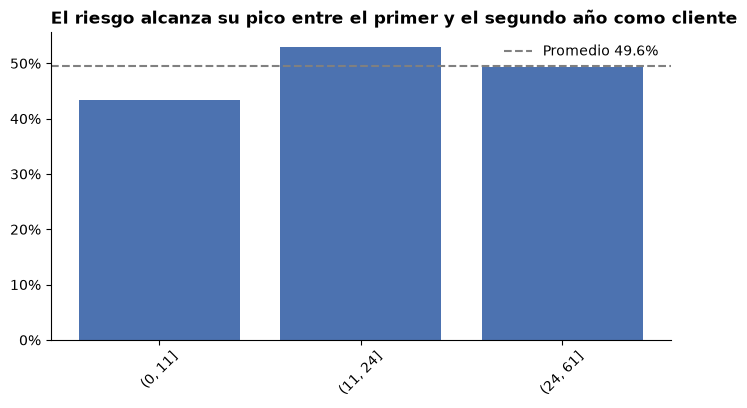

In [7]:

fig = graficar_tasa(
    tasa_por_mes,
    "El riesgo alcanza su pico entre el primer y el segundo año como cliente",
    promedio
)